# IPL Match Intelligence & Pattern Mining
**Data Mining Project** · BCA · Team: Sachin (24BCA10079), Shivam (24BCA10080) · Mentor: Ms. Jyoti

Mining 10 IPL seasons (2008–2017) with **K-Means clustering**, **Apriori association rules** and a **Decision Tree classifier**, all in Python (pandas, scikit-learn, mlxtend).

## 1. Load the data
`matches.csv` has one row per match (636 matches). `deliveries.csv` has one row per ball (150,460 balls) and is used only to summarise innings scores and wickets.

In [28]:
import zipfile
from google.colab import files

uploaded = files.upload()                  # choose the zip
zipname = list(uploaded.keys())[0]

with zipfile.ZipFile(zipname) as z:
    z.extractall(".")
    print(z.namelist())

Saving archive (1).zip to archive (1).zip
['deliveries.csv', 'matches.csv']


In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

matches = pd.read_csv("matches.csv")
deliveries = pd.read_csv("deliveries.csv")

print(matches.shape)
print(deliveries.shape)
matches.head()

(636, 18)
(150460, 21)


,id,season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2,umpire3
0,1,2017,Hyderabad,2017-04-05,Sunrisers Hyderabad,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,0,Sunrisers Hyderabad,35,0,Yuvraj Singh,"Rajiv Gandhi International Stadium, Uppal",AY Dandekar,NJ Llong,NaN
1,2,2017,Pune,2017-04-06,Mumbai Indians,Rising Pune Supergiant,Rising Pune Supergiant,field,normal,0,Rising Pune Supergiant,0,7,SPD Smith,Maharashtra Cricket Association Stadium,A Nand Kishore,S Ravi,NaN
2,3,2017,Rajkot,2017-04-07,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,field,normal,0,Kolkata Knight Riders,0,10,CA Lynn,Saurashtra Cricket Association Stadium,Nitin Menon,CK Nandan,NaN
3,4,2017,Indore,2017-04-08,Rising Pune Supergiant,Kings XI Punjab,Kings XI Punjab,field,normal,0,Kings XI Punjab,0,6,GJ Maxwell,Holkar Cricket Stadium,AK Chaudhary,C Shamshuddin,NaN
4,5,2017,Bangalore,2017-04-08,Royal Challengers Bangalore,Delhi Daredevils,Royal Challengers Bangalore,bat,normal,0,Royal Challengers Bangalore,15,0,KM Jadhav,M Chinnaswamy Stadium,NaN,NaN,NaN


## 2. Clean the data


In [30]:
df = matches.copy()

# drop columns we don't need
df = df.drop(columns=["umpire1", "umpire2", "umpire3"])

# fix the duplicate team name
for col in ["team1", "team2", "toss_winner", "winner"]:
    df[col] = df[col].replace("Rising Pune Supergiants", "Rising Pune Supergiant")

# fill missing values
df["city"] = df["city"].fillna("Unknown")
df["winner"] = df["winner"].fillna("No Result")
df["player_of_match"] = df["player_of_match"].fillna("None")

# new helpful columns
df["toss_winner_won"] = (df["toss_winner"] == df["winner"]).map({True: "Yes", False: "No"})

print(df.shape)
print("Missing values left:", df.isnull().sum().sum())
df.head()

(636, 16)
Missing values left: 0


,id,season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,toss_winner_won
0,1,2017,Hyderabad,2017-04-05,Sunrisers Hyderabad,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,0,Sunrisers Hyderabad,35,0,Yuvraj Singh,"Rajiv Gandhi International Stadium, Uppal",No
1,2,2017,Pune,2017-04-06,Mumbai Indians,Rising Pune Supergiant,Rising Pune Supergiant,field,normal,0,Rising Pune Supergiant,0,7,SPD Smith,Maharashtra Cricket Association Stadium,Yes
2,3,2017,Rajkot,2017-04-07,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,field,normal,0,Kolkata Knight Riders,0,10,CA Lynn,Saurashtra Cricket Association Stadium,Yes
3,4,2017,Indore,2017-04-08,Rising Pune Supergiant,Kings XI Punjab,Kings XI Punjab,field,normal,0,Kings XI Punjab,0,6,GJ Maxwell,Holkar Cricket Stadium,Yes
4,5,2017,Bangalore,2017-04-08,Royal Challengers Bangalore,Delhi Daredevils,Royal Challengers Bangalore,bat,normal,0,Royal Challengers Bangalore,15,0,KM Jadhav,M Chinnaswamy Stadium,Yes


## 3. Exploratory data analysis (EDA)
### Matches per season

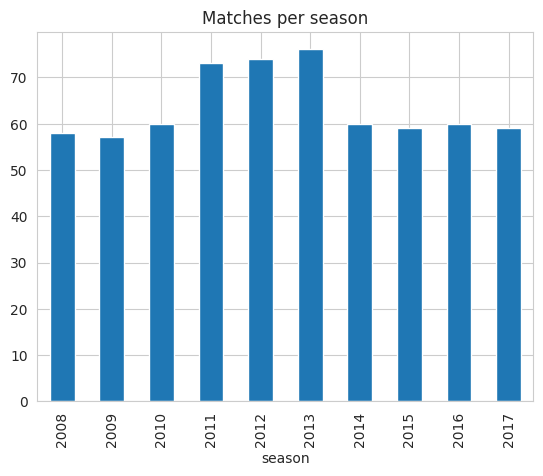

In [31]:
df["season"].value_counts().sort_index().plot(kind="bar")
plt.title("Matches per season")
plt.show()

### Wins per team

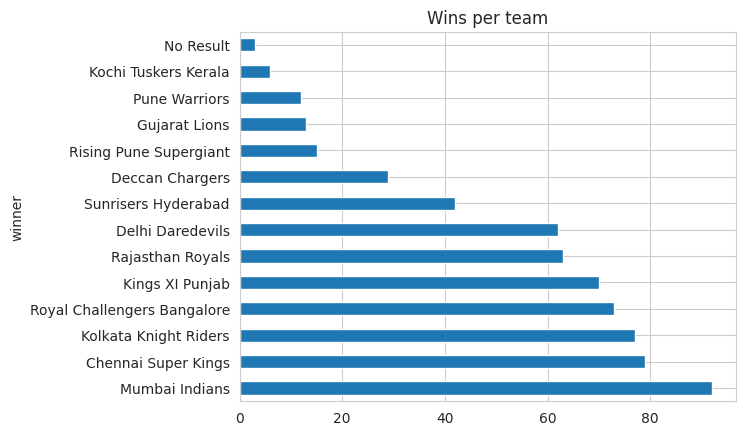

In [32]:
df["winner"].value_counts().plot(kind="barh")
plt.title("Wins per team")
plt.show()

### Toss decision (bat or field)

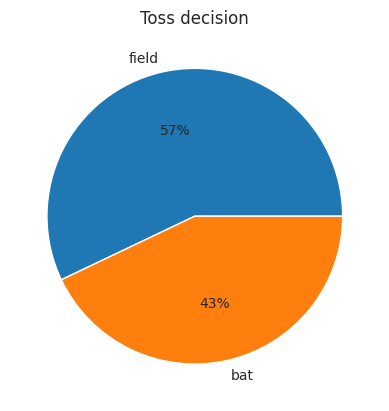

In [33]:
df["toss_decision"].value_counts().plot(kind="pie", autopct="%1.0f%%")
plt.title("Toss decision")
plt.ylabel("")
plt.show()

### Did the toss winner win the match?

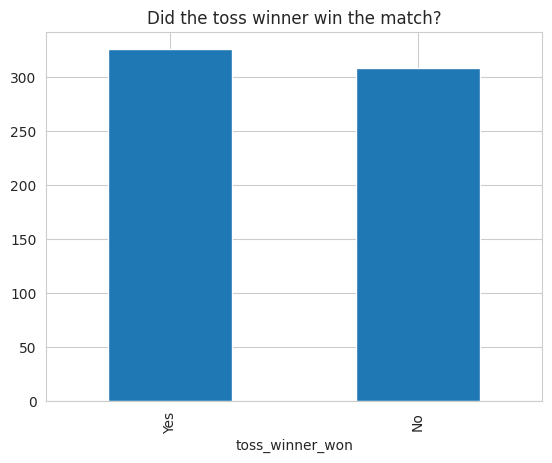

In [34]:
df[df["winner"] != "No Result"]["toss_winner_won"].value_counts().plot(kind="bar")
plt.title("Did the toss winner win the match?")
plt.show()

### Most-used venues

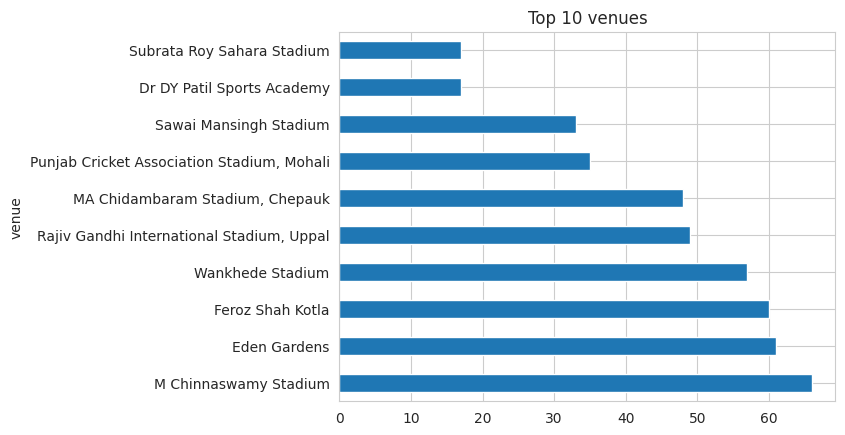

In [35]:
df["venue"].value_counts().head(10).plot(kind="barh")
plt.title("Top 10 venues")
plt.show()

## 4. Add innings statistics from `deliveries.csv`


In [36]:
d = deliveries[deliveries["inning"] <= 2].copy()          # ignore super overs
d["batting_team"] = d["batting_team"].replace("Rising Pune Supergiants", "Rising Pune Supergiant")

runs = d.groupby(["match_id", "inning"])["total_runs"].sum().unstack()
runs.columns = ["score_inn1", "score_inn2"]

d["wicket"] = d["player_dismissed"].notna().astype(int)
wkts = d.groupby(["match_id", "inning"])["wicket"].sum().unstack()
wkts.columns = ["wkts_inn1", "wkts_inn2"]

match_stats = runs.join(wkts)
match_stats.head()

,score_inn1,score_inn2,wkts_inn1,wkts_inn2
match_id,,,,
1,207.0,172.0,4.0,10.0
2,184.0,187.0,8.0,3.0
3,183.0,184.0,4.0,0.0
4,163.0,164.0,6.0,4.0
5,157.0,142.0,8.0,9.0


In [37]:
df2 = df.merge(match_stats, left_on="id", right_index=True, how="left")

print(df2.shape)
print(df2[["score_inn1", "score_inn2", "wkts_inn1", "wkts_inn2"]].isnull().sum())
df2.head()

(636, 20)
score_inn1    0
score_inn2    2
wkts_inn1     0
wkts_inn2     2
dtype: int64


,id,season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,toss_winner_won,score_inn1,score_inn2,wkts_inn1,wkts_inn2
0,1,2017,Hyderabad,2017-04-05,Sunrisers Hyderabad,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,0,Sunrisers Hyderabad,35,0,Yuvraj Singh,"Rajiv Gandhi International Stadium, Uppal",No,207.0,172.0,4.0,10.0
1,2,2017,Pune,2017-04-06,Mumbai Indians,Rising Pune Supergiant,Rising Pune Supergiant,field,normal,0,Rising Pune Supergiant,0,7,SPD Smith,Maharashtra Cricket Association Stadium,Yes,184.0,187.0,8.0,3.0
2,3,2017,Rajkot,2017-04-07,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,field,normal,0,Kolkata Knight Riders,0,10,CA Lynn,Saurashtra Cricket Association Stadium,Yes,183.0,184.0,4.0,0.0
3,4,2017,Indore,2017-04-08,Rising Pune Supergiant,Kings XI Punjab,Kings XI Punjab,field,normal,0,Kings XI Punjab,0,6,GJ Maxwell,Holkar Cricket Stadium,Yes,163.0,164.0,6.0,4.0
4,5,2017,Bangalore,2017-04-08,Royal Challengers Bangalore,Delhi Daredevils,Royal Challengers Bangalore,bat,normal,0,Royal Challengers Bangalore,15,0,KM Jadhav,M Chinnaswamy Stadium,Yes,157.0,142.0,8.0,9.0


### Team scoring summary (average, highest score, innings played)

In [38]:
team_runs = d.groupby(["match_id", "batting_team"])["total_runs"].sum().reset_index()

team_summary = team_runs.groupby("batting_team")["total_runs"].agg(
    avg_score="mean", highest="max", matches="count").round(1)

team_summary.sort_values("avg_score", ascending=False)

,avg_score,highest,matches
batting_team,,,
Gujarat Lions,161.9,208,30
Chennai Super Kings,159.5,246,131
Mumbai Indians,156.1,223,157
Kings XI Punjab,155.7,232,148
Royal Challengers Bangalore,154.0,263,152
Sunrisers Hyderabad,153.1,209,76
Deccan Chargers,152.8,214,75
Rising Pune Supergiant,151.1,195,30
Rajasthan Royals,151.0,223,117


## 5. K-Means clustering of matches
Features: both innings' runs and wickets, win-by-runs and win-by-wickets, all standardised.

In [39]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cols = ["score_inn1", "score_inn2", "wkts_inn1", "wkts_inn2", "win_by_runs", "win_by_wickets"]
km_df = df2.dropna(subset=cols).copy()

X = StandardScaler().fit_transform(km_df[cols])
print(X.shape)

(634, 6)


### Choosing k (elbow + silhouette)

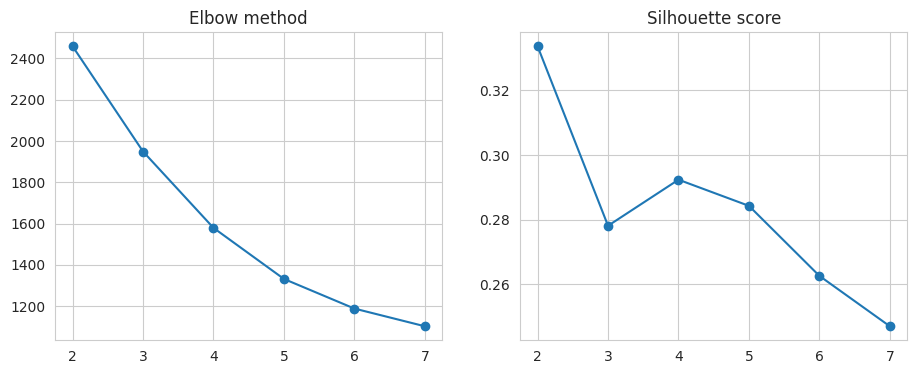

{2: np.float64(0.334), 3: np.float64(0.278), 4: np.float64(0.292), 5: np.float64(0.284), 6: np.float64(0.263), 7: np.float64(0.247)}


In [40]:
inertia, sil = [], []
ks = range(2, 8)

for k in ks:
    model = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    inertia.append(model.inertia_)
    sil.append(silhouette_score(X, model.labels_))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, inertia, marker="o"); ax[0].set_title("Elbow method")
ax[1].plot(ks, sil, marker="o");     ax[1].set_title("Silhouette score")
plt.show()

print(dict(zip(ks, np.round(sil, 3))))

### Fit K-Means with k = 3


In [41]:
best_k = 3

kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10).fit(X)
km_df["cluster"] = kmeans.labels_

km_df.groupby("cluster")[cols].mean().round(1)

,score_inn1,score_inn2,wkts_inn1,wkts_inn2,win_by_runs,win_by_wickets
cluster,,,,,,
0,127.3,124.6,8.0,3.2,0.8,6.3
1,173.4,141.1,5.4,8.3,32.1,0.0
2,171.9,173.1,5.2,4.3,1.0,5.2


### Cluster plot and interpretation
| Cluster | Avg 1st inns | Avg 2nd inns | Typical result | Meaning |
|---|---|---|---|---|
| 0 (181 matches) | 127 | 125 | chasing team wins by ~6 wickets | **Low-scoring matches won by the chasing team** |
| 1 (261 matches) | 173 | 141 | batting-first team wins by ~32 runs | **Matches won by the team batting first** |
| 2 (192 matches) | 172 | 173 | chasing team wins by ~5 wickets | **High-scoring matches won by the chasing team** |

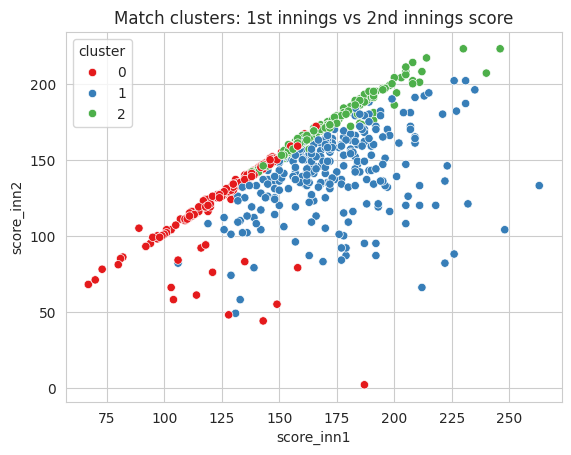

cluster
1    261
2    192
0    181
Name: count, dtype: int64


In [42]:
sns.scatterplot(data=km_df, x="score_inn1", y="score_inn2", hue="cluster", palette="Set1")
plt.title("Match clusters: 1st innings vs 2nd innings score")
plt.show()

print(km_df["cluster"].value_counts())

## 6. Association rules (Apriori)


In [43]:
from mlxtend.frequent_patterns import apriori, association_rules

# keep only normal matches (no ties, no rain/no-result)
ap = df2[df2["result"] == "normal"].dropna(subset=["score_inn1"]).copy()

# turn numbers into simple labels
ap["win_type"] = np.where(ap["win_by_runs"] > 0, "BatFirst_Won", "Chase_Won")
ap["score_level"] = pd.cut(ap["score_inn1"], [0, 140, 170, 400], labels=["Low", "Medium", "High"])

# keep the 6 most-used venues, call the rest "Other"
top_venues = ap["venue"].value_counts().head(6).index
ap["venue_group"] = np.where(ap["venue"].isin(top_venues), ap["venue"], "Other")

ap[["toss_decision", "win_type", "score_level", "venue_group"]].head()


,toss_decision,win_type,score_level,venue_group
0,field,BatFirst_Won,High,"Rajiv Gandhi International Stadium, Uppal"
1,field,Chase_Won,High,Other
2,field,Chase_Won,High,Other
3,field,Chase_Won,Medium,Other
4,bat,BatFirst_Won,Medium,M Chinnaswamy Stadium


In [44]:
import warnings
warnings.filterwarnings("ignore")

In [45]:
# pick the columns to look at (no toss_winner_won, it would give obvious rules)
data = ap[["toss_decision", "win_type", "score_level", "venue_group"]].astype(str)

# convert to True/False table
basket = pd.get_dummies(data, dtype=bool)

# step 1: find items that appear together often
frequent = apriori(basket, min_support=0.05, use_colnames=True)

# step 2: make rules from them
rules = association_rules(frequent, metric="confidence", min_threshold=0.55)

# keep only useful rules (lift > 1) with ONE result on the right side
rules = rules[(rules["lift"] > 1) & (rules["consequents"].apply(len) == 1)]
rules = rules.sort_values("lift", ascending=False)

# make the text readable
rules["IF"] = rules["antecedents"].apply(lambda x: ", ".join(x))
rules["THEN"] = rules["consequents"].apply(lambda x: ", ".join(x))

rules[["IF", "THEN", "support", "confidence", "lift"]].head(10).round(2)

,IF,THEN,support,confidence,lift
0,"venue_group_MA Chidambaram Stadium, Chepauk",toss_decision_bat,0.05,0.72,1.68
14,"toss_decision_bat, score_level_High",win_type_BatFirst_Won,0.10,0.73,1.60
18,"toss_decision_field, win_type_BatFirst_Won",score_level_High,0.15,0.57,1.56
5,venue_group_M Chinnaswamy Stadium,toss_decision_field,0.09,0.86,1.50
33,"toss_decision_field, venue_group_Other, score_...",win_type_Chase_Won,0.05,0.81,1.49
28,"venue_group_Other, score_level_Low",win_type_Chase_Won,0.09,0.79,1.47
8,score_level_High,win_type_BatFirst_Won,0.24,0.67,1.46
27,"venue_group_Other, score_level_High",win_type_BatFirst_Won,0.10,0.66,1.44
21,"toss_decision_field, score_level_Low",win_type_Chase_Won,0.11,0.78,1.43
9,score_level_Low,win_type_Chase_Won,0.19,0.78,1.43


### Top rules (by lift)


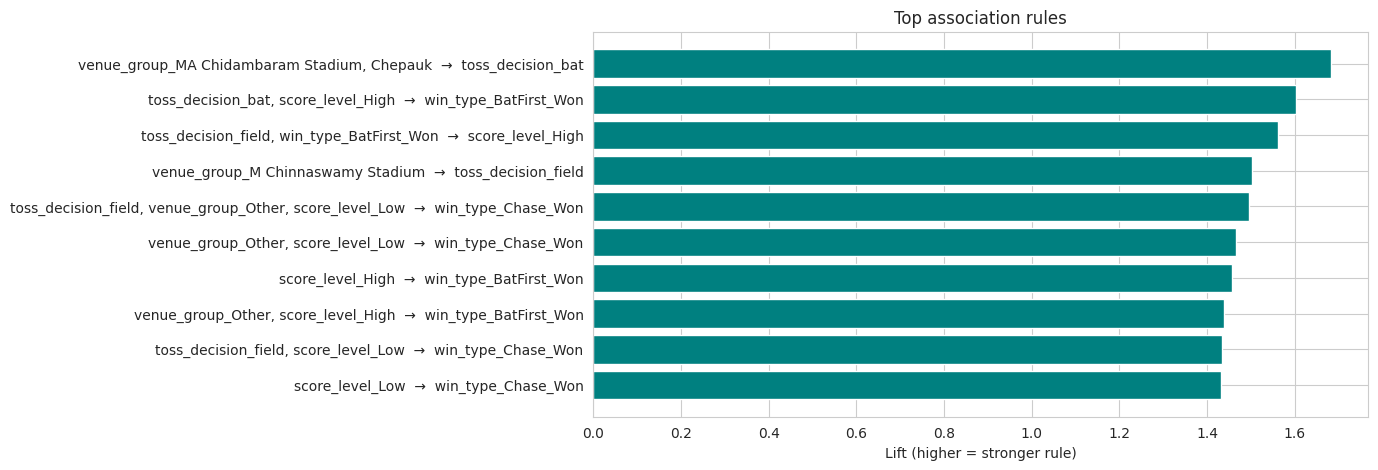

In [46]:
top = rules.head(10)
plt.figure(figsize=(10, 5))
plt.barh(top["IF"] + "  →  " + top["THEN"], top["lift"], color="teal")
plt.xlabel("Lift (higher = stronger rule)")
plt.title("Top association rules")
plt.gca().invert_yaxis()
plt.show()

## 7. Decision Tree classification


In [47]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# inputs (X) and what we want to predict (y)
feat = ap[["toss_decision", "venue_group", "team1", "team2"]].copy()
feat["season"] = ap["season"]
feat["score_inn1"] = ap["score_inn1"]
X = pd.get_dummies(feat, dtype=int)
y = ap["win_type"]

# 80% to train, 20% to test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# train the tree
tree = DecisionTreeClassifier(max_depth=4, random_state=42)
tree.fit(X_train, y_train)

pred = tree.predict(X_test)
print("Guessing the common class always gives:", round(y.value_counts(normalize=True).max(), 3))
print("Our tree accuracy on test data:", round(accuracy_score(y_test, pred), 3))
print("Cross-validation accuracy:", round(cross_val_score(tree, X, y, cv=5).mean(), 3))
print(classification_report(y_test, pred))

Guessing the common class always gives: 0.542
Our tree accuracy on test data: 0.651
Cross-validation accuracy: 0.628
              precision    recall  f1-score   support

BatFirst_Won       0.62      0.62      0.62        58
   Chase_Won       0.68      0.68      0.68        68

    accuracy                           0.65       126
   macro avg       0.65      0.65      0.65       126
weighted avg       0.65      0.65      0.65       126



### Tree, confusion matrix and feature importance


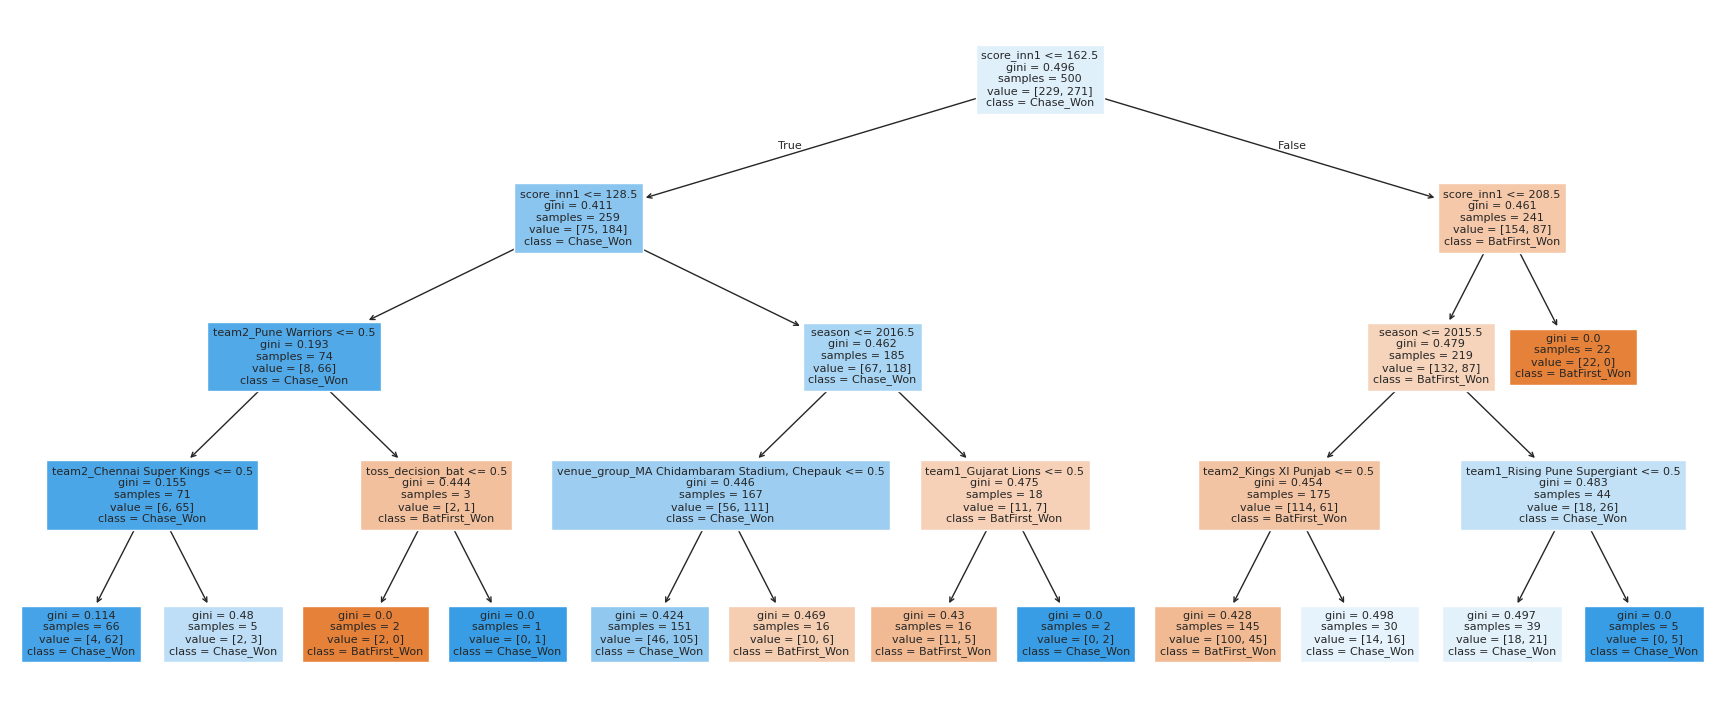

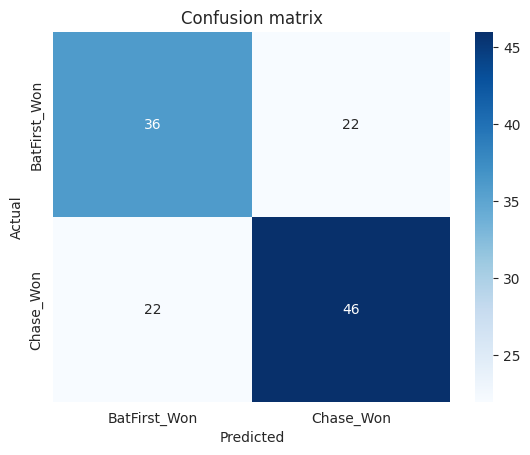

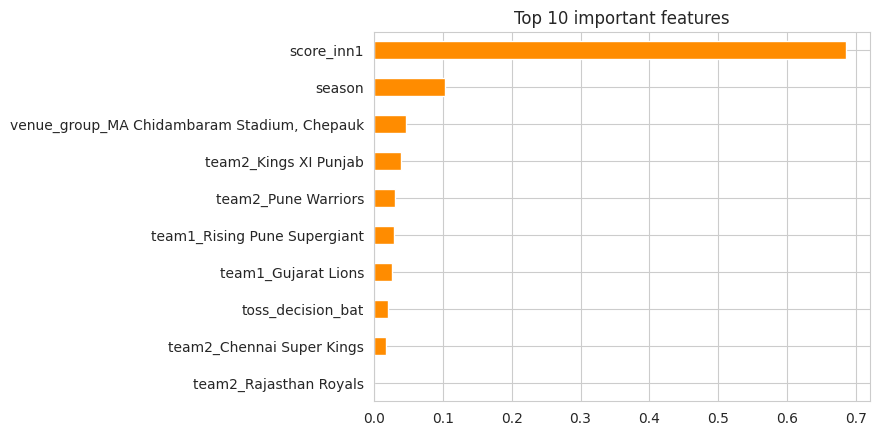

In [48]:
# the tree
plt.figure(figsize=(22, 9))
plot_tree(tree, feature_names=X.columns, class_names=tree.classes_, filled=True, fontsize=8)
plt.show()

# confusion matrix
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=tree.classes_, yticklabels=tree.classes_)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix")
plt.show()

# most important features
imp = pd.Series(tree.feature_importances_, index=X.columns).sort_values().tail(10)
imp.plot(kind="barh", color="darkorange", title="Top 10 important features")
plt.show()

## 8. Conclusion
| Method | Main finding |
|---|---|
| K-Means | Matches fall into 3 types: low-scoring chases, high-scoring chases and batting-first wins |
| Apriori | High totals are defended, low totals are chased, and toss decisions depend on the venue |
| Decision Tree | 65% test accuracy (63% cross-validated) against a 54% baseline; first-innings score is the key factor |

**Limitations:** only 636 matches, match-level data (no pitch or player-form information), and cricket results are inherently hard to predict.

**Future scope:** more seasons, player-level analysis from ball-by-ball data, more advanced models and an interactive dashboard.